# Современные расписания learning rate: WSD и Schedule-Free

**Докладчик:** Родэ Михаил  **Группа:** ИУ9-72Б  **Дата:** 12.11.2026

Постановка как в РК1 (вариант 6): MNIST (6000 train, 2000 test), MLP 784 → 64 (ReLU) → 10 (softmax), mini-batch SGD без momentum, батч 64, 20 эпох (1880 шагов), пиковый lr = 1, 5 seed начальных весов.

In [1]:
import os, math, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

SEEDS = [60, 61, 62, 63, 64]
EPOCHS, BATCH, HIDDEN = 20, 64, 64

path = 'data/mnist.npz'
if not os.path.exists(path):
    os.makedirs('data', exist_ok=True)
    urllib.request.urlretrieve('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz', path)
d = np.load(path)
rng = np.random.default_rng(0)
i, j = rng.permutation(60000), rng.permutation(10000)[:2000]
X, Xt = d['x_train'].reshape(-1, 784) / 255, d['x_test'].reshape(-1, 784) / 255
Xtr, ytr = X[i[:6000]], d['y_train'][i[:6000]]
Xte, yte = Xt[j], d['y_test'][j]
STEPS = math.ceil(len(Xtr) / BATCH)      # шагов за эпоху
T_MAX = EPOCHS * STEPS                    # шагов за 20 эпох
print('шагов за эпоху:', STEPS, '| T_MAX =', T_MAX)

шагов за эпоху: 94 | T_MAX = 1880


In [2]:
def init(seed):                                     # He-инициализация
    r = np.random.default_rng(seed)
    return [r.normal(0, np.sqrt(2 / 784), (784, HIDDEN)), np.zeros(HIDDEN),
            r.normal(0, np.sqrt(1 / HIDDEN), (HIDDEN, 10)), np.zeros(10)]

def forward(P, X):
    W1, b1, W2, b2 = P
    z1 = X @ W1 + b1
    h = np.maximum(z1, 0)
    z2 = h @ W2 + b2
    z2 = z2 - z2.max(1, keepdims=True)
    return z1, h, z2 - np.log(np.exp(z2).sum(1, keepdims=True))

def accuracy(P):
    return (forward(P, Xte)[2].argmax(1) == yte).mean()

def loss_and_grads(P, X, y):                         # backprop, как в РК1
    W1, b1, W2, b2 = P
    z1, h, logp = forward(P, X)
    loss = -logp[np.arange(len(y)), y].mean()
    d2 = np.exp(logp); d2[np.arange(len(y)), y] -= 1; d2 /= len(y)
    d1 = (d2 @ W2.T) * (z1 > 0)
    return loss, [X.T @ d1, d1.sum(0), h.T @ d2, d2.sum(0)]

def batch_at(t):                                     # одинаковый порядок батчей во всех запусках
    e, k = divmod(t, STEPS)
    perm = np.random.default_rng([1, e]).permutation(len(Xtr))
    return perm[k * BATCH:(k + 1) * BATCH]

def train(sched, seed, t_end=T_MAX, P=None, t_start=0):
    """Обычный SGD с расписанием sched(t). Можно продолжить с весов P с шага t_start."""
    P = init(seed) if P is None else [p.copy() for p in P]
    losses = []
    for t in range(t_start, t_end):
        b = batch_at(t)
        loss, g = loss_and_grads(P, Xtr[b], ytr[b])
        for p, gi in zip(P, g):
            p -= sched(t) * gi
        losses.append(loss)
    return P, losses

def train_schedule_free(lr, seed, t_end=T_MAX, beta=0.9, warmup=190, checkpoints=()):
    """Schedule-Free SGD: z — шаги SGD, x — среднее z (на нём оцениваем), градиент в точке y."""
    z = init(seed); x = [p.copy() for p in z]
    losses, saved = [], {}
    for t in range(t_end):
        y_ = [(1 - beta) * zi + beta * xi for zi, xi in zip(z, x)]
        b = batch_at(t)
        loss, g = loss_and_grads(y_, Xtr[b], ytr[b])
        step = lr * min(1, (t // 10 * 10 + 1) / warmup)          # только warmup, без затухания
        for zi, gi in zip(z, g):
            zi -= step * gi
        c = 1 / (t + 1)
        for xi, zi in zip(x, z):
            xi *= 1 - c; xi += c * zi
        losses.append(loss)
        if t + 1 in checkpoints:
            saved[t + 1] = [p.copy() for p in x]
    return x, losses, saved

def summary(res, base):
    rows = []
    b = np.array(res[base])
    for name, a in res.items():
        a = np.array(a)
        rows.append({'метод': name, 'test acc': a.mean(), 'std': a.std(ddof=1),
                     'CI95 ±': stats.t.ppf(0.975, 4) * a.std(ddof=1) / np.sqrt(5),
                     'лучше базы по seed': '—' if name == base else f'{(a > b).sum()}/5'})
    return pd.DataFrame(rows).set_index('метод').round(4)

## 1. Расписания

Пиковый lr = 1, $lr_{min} = 0.01$, warmup 190 шагов (10%), lr меняется раз в 10 шагов, как в РК1. У WSD cooldown — последние 20% шагов, lr линейно падает до 0.

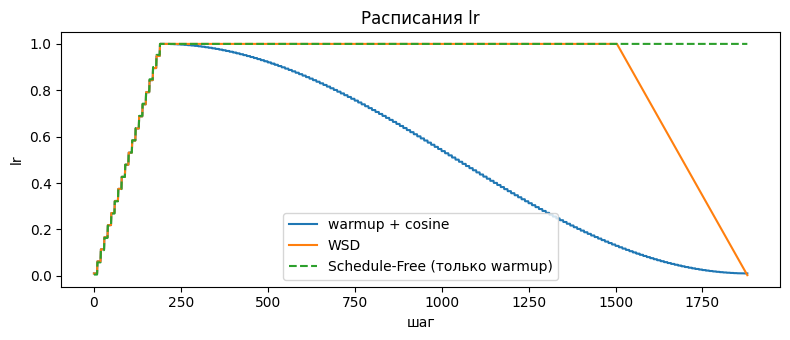

In [3]:
LR0, LR_MIN, T_WARM = 1.0, 0.01, 190
q = lambda t: t // 10 * 10

def warmup_cosine(T, tw=T_WARM):
    def f(t):
        if q(t) < tw:
            return LR_MIN + (LR0 - LR_MIN) * q(t) / tw
        return LR_MIN + (LR0 - LR_MIN) / 2 * (1 + math.cos(math.pi * q(t - tw) / (T - tw + 1)))
    return f

def wsd(T, tw=T_WARM, decay=0.2):
    t_decay = int(decay * T)
    def f(t):
        if q(t) < tw:
            return LR_MIN + (LR0 - LR_MIN) * q(t) / tw            # warmup
        if t < T - t_decay:
            return LR0                                             # stable
        return LR0 * (T - t) / t_decay                             # decay (cooldown)
    return f

steps = np.arange(T_MAX)
plt.figure(figsize=(8, 3.5))
plt.plot(steps, [warmup_cosine(T_MAX)(t) for t in steps], label='warmup + cosine')
plt.plot(steps, [wsd(T_MAX)(t) for t in steps], label='WSD')
plt.plot(steps, [LR0 * min(1, (q(t) + 1) / T_WARM) for t in steps], '--', label='Schedule-Free (только warmup)')
plt.xlabel('шаг'); plt.ylabel('lr'); plt.title('Расписания lr'); plt.legend(); plt.tight_layout(); plt.show()

## 2. Эксперимент 1: сравнение на полном обучении (20 эпох, 5 seed)

База — warmup + cosine, лучший вариант из РК1. У Schedule-Free два lr: 1 (как у всех) и 3, потому что авторы советуют брать для него lr больше.

In [4]:
res, curves = {}, {}
for name, sched in {'const lr = 1': lambda t: LR0,
                    'warmup + cosine': warmup_cosine(T_MAX),
                    'WSD': wsd(T_MAX)}.items():
    runs = [train(sched, s) for s in SEEDS]
    res[name] = [accuracy(P) for P, _ in runs]
    curves[name] = np.mean([l for _, l in runs], 0)
for lr in [1.0, 3.0]:
    runs = [train_schedule_free(lr, s) for s in SEEDS]
    res[f'Schedule-Free, lr = {lr:g}'] = [accuracy(x) for x, _, _ in runs]
    curves[f'Schedule-Free, lr = {lr:g}'] = np.mean([l for _, l, _ in runs], 0)
display(summary(res, base='warmup + cosine'))

,test acc,std,CI95 ±,лучше базы по seed
метод,,,,
const lr = 1,0.9404,0.0034,0.0043,0/5
warmup + cosine,0.9560,0.0026,0.0032,—
WSD,0.9569,0.0028,0.0035,3/5
"Schedule-Free, lr = 1",0.9443,0.0020,0.0025,0/5
"Schedule-Free, lr = 3",0.9500,0.0038,0.0047,0/5


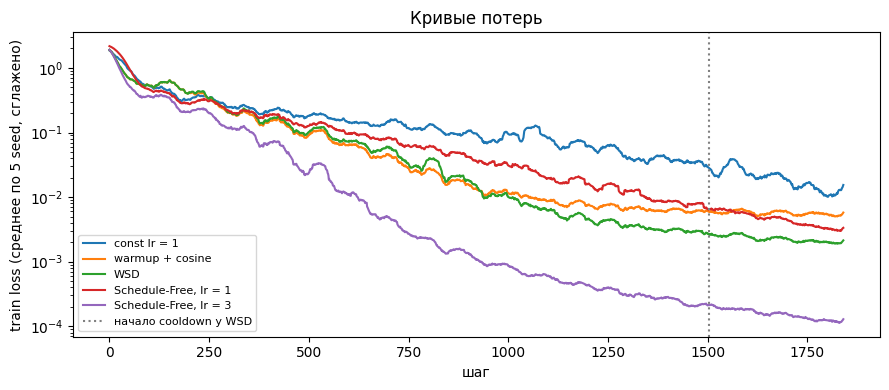

In [5]:
smooth = lambda y, w=40: np.convolve(y, np.ones(w) / w, mode='valid')
plt.figure(figsize=(9, 4))
for name, l in curves.items():
    plt.plot(smooth(l), label=name)
plt.axvline(T_MAX * 0.8, color='gray', ls=':', label='начало cooldown у WSD')
plt.yscale('log'); plt.xlabel('шаг'); plt.ylabel('train loss (среднее по 5 seed, сглажено)')
plt.title('Кривые потерь'); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Эксперимент 2: модели на 5, 10 и 20 эпох («anytime»)

Хотим три модели: на 5, 10 и 20 эпох.
- **Cosine:** форма зависит от T, поэтому три отдельных обучения: 5 + 10 + 20 = 35 эпох.
- **WSD:** одно общее обучение со стабильным lr; из него сохраняем точки на 80% каждого бюджета (4, 8 и 16 эпох) и от каждой делаем cooldown (1, 2 и 4 эпохи). Итого 16 + 7 = 23 эпохи.
- **Schedule-Free:** одно обучение на 20 эпох, веса $x$ сохраняем на 5, 10 и 20 эпохах.

Warmup здесь 50 шагов (около 10% от самого короткого бюджета), чтобы он был одинаковым у всех.

In [6]:
BUDGETS = [5, 10, 20]
TW2 = 50
any_res = {'warmup + cosine': {B: [] for B in BUDGETS}, 'WSD': {B: [] for B in BUDGETS},
           'Schedule-Free (lr = 3)': {B: [] for B in BUDGETS}}

for s in SEEDS:
    # cosine: отдельное обучение под каждый бюджет
    for B in BUDGETS:
        P, _ = train(warmup_cosine(B * STEPS, tw=TW2), s, t_end=B * STEPS)
        any_res['warmup + cosine'][B].append(accuracy(P))

    # WSD: одна стабильная фаза, ответвления-cooldown
    stable = lambda t: LR_MIN + (LR0 - LR_MIN) * q(t) / TW2 if q(t) < TW2 else LR0
    P, t = init(s), 0
    for B in BUDGETS:
        t_cd = int(0.8 * B * STEPS)                                  # точка начала cooldown
        P, _ = train(stable, s, t_end=t_cd, P=P, t_start=t)          # продолжаем стабильную фазу
        t = t_cd
        Pb, _ = train(wsd(B * STEPS, tw=TW2), s, t_end=B * STEPS, P=P, t_start=t_cd)   # ответвление
        any_res['WSD'][B].append(accuracy(Pb))

    # Schedule-Free: одно обучение, берём x в нужные моменты
    _, _, saved = train_schedule_free(3.0, s, warmup=TW2, checkpoints={B * STEPS for B in BUDGETS})
    for B in BUDGETS:
        any_res['Schedule-Free (lr = 3)'][B].append(accuracy(saved[B * STEPS]))

cost = {'warmup + cosine': sum(BUDGETS), 'WSD': 0.8 * max(BUDGETS) + 0.2 * sum(BUDGETS), 'Schedule-Free (lr = 3)': max(BUDGETS)}
table = pd.DataFrame({m: {**{f'{B} эпох': np.mean(v[B]) for B in BUDGETS}, 'всего эпох обучения': cost[m]}
                      for m, v in any_res.items()}).T
display(table.round(4))

,5 эпох,10 эпох,20 эпох,всего эпох обучения
warmup + cosine,0.9424,0.9459,0.9484,35.0
WSD,0.9467,0.9497,0.9489,23.0
Schedule-Free (lr = 3),0.9493,0.9541,0.9540,20.0


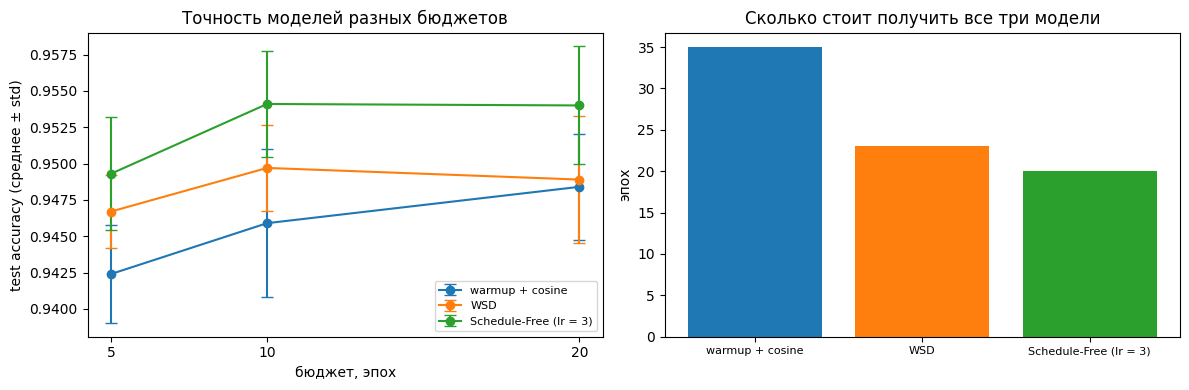

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, v in any_res.items():
    ax[0].errorbar(BUDGETS, [np.mean(v[B]) for B in BUDGETS], yerr=[np.std(v[B], ddof=1) for B in BUDGETS],
                   marker='o', capsize=4, label=m)
ax[0].set(xlabel='бюджет, эпох', ylabel='test accuracy (среднее ± std)', title='Точность моделей разных бюджетов')
ax[0].set_xticks(BUDGETS); ax[0].legend(fontsize=8)
ax[1].bar(list(cost), list(cost.values()), color=['tab:blue', 'tab:orange', 'tab:green'])
ax[1].set(ylabel='эпох', title='Сколько стоит получить все три модели')
ax[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()